# Dataset Creation & Analysis – RainTomorrow (Open-Meteo)
**ML 364-1-1811 – Project Part A**

Notebook structure (follows the report):
1. Loading the data produced by `data_collection.py` → `sensing.py`
2. Data understanding – variable dictionary, prior probabilities, balance
3. Relationships between features and suspected predictors
4. Data quality – missing values, illogical values, duplicates, gaps
5. Data preparation – feature selection, imputation, discretization, feature engineering
6. Extra analysis – naive baselines and generalisation to future data

Every figure is saved to `figures/` and is used in the report.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
np.random.seed(42)

ROOT = Path.cwd()
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "figures"
FIG.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
                     "axes.titleweight": "bold"})
CITY_ORDER = ["London", "Berlin", "Vancouver", "New York", "Tokyo", "Sydney"]
PALETTE = dict(zip(CITY_ORDER, sns.color_palette("tab10", 6)))
RAIN_COLORS = {0: "#E0A040", 1: "#2F6DB5"}

def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

## 1. Loading the data

In [2]:
sensed = pd.read_csv(RAW / "sensed_data.csv", parse_dates=["date"])
df = pd.read_csv(PROC / "final_dataset.csv", parse_dates=["date"])
CITY_ORDER = [c for c in CITY_ORDER if c in set(df.location)]
print("sensed_data :", sensed.shape, "  final_dataset :", df.shape)
print("rows removed by sensing (last day of each location):", len(sensed) - len(df))
summary = df.groupby("location").agg(first_day=("date", "min"), last_day=("date", "max"), rows=("date", "size"))
summary.loc[CITY_ORDER]

sensed_data : (36888, 19)   final_dataset : (36882, 20)
rows removed by sensing (last day of each location): 6


,first_day,last_day,rows
location,,,
London,2010-01-01,2026-10-30,6147
Berlin,2010-01-01,2026-10-30,6147
Vancouver,2010-01-01,2026-10-30,6147
New York,2010-01-01,2026-10-30,6147
Tokyo,2010-01-01,2026-10-30,6147
Sydney,2010-01-01,2026-10-30,6147


In [3]:
df.head()

,location,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_direction_10m_dominant,relative_humidity_2m_mean,dew_point_2m_mean,pressure_msl_mean,cloud_cover_mean,sunshine_duration,wind_gusts_10m_max,snowfall_sum,RainTomorrow
0,Berlin,2010-01-01,73,-1.7,-3.2,-2.6,-7.2,3.2,0.0,12.0,16.3,44,86,-4.7,998.2,99,0.00,31.3,2.24,1
1,Berlin,2010-01-02,71,-1.3,-5.8,-3.2,-7.6,1.1,0.0,9.0,15.8,324,90,-4.7,1011.5,97,2114.82,23.0,1.19,0
2,Berlin,2010-01-03,71,-4.9,-9.0,-6.8,-10.5,0.0,0.0,0.0,7.3,49,93,-7.7,1020.2,94,12470.87,19.4,0.14,0
3,Berlin,2010-01-04,3,-6.3,-9.6,-7.7,-12.1,0.0,0.0,0.0,13.0,215,90,-9.1,1017.6,92,0.00,23.8,0.00,0
4,Berlin,2010-01-05,3,-5.5,-11.8,-7.8,-12.3,0.0,0.0,0.0,11.2,176,88,-9.5,1010.3,90,18052.82,21.6,0.00,0


In [4]:
# Sanity check of the target: RainTomorrow must equal next-day precipitation_sum >= 1.0 mm
chk = sensed.sort_values(["location", "date"]).copy()
chk["next_p"] = chk.groupby("location")["precipitation_sum"].shift(-1)
m = df.merge(chk[["location", "date", "next_p"]], on=["location", "date"])
print("label mismatches:", int(((m.next_p >= 1.0).astype(int) != m.RainTomorrow).sum()))
print("duplicate (location,date) rows:", int(df.duplicated(["location", "date"]).sum()))

label mismatches: 0
duplicate (location,date) rows: 0


## 2. Data understanding
### 2.1 Variable dictionary

In [5]:
var_info = [
 ("location", "City the row belongs to", "-", "Categorical, nominal (6 values)"),
 ("date", "Calendar day (local time zone, timezone=auto)", "-", "Date / ordinal"),
 ("weather_code", "Most severe WMO weather code of the day", "WMO code", "Categorical (partly ordinal by severity)"),
 ("temperature_2m_max", "Max air temperature at 2 m", "°C", "Continuous"),
 ("temperature_2m_min", "Min air temperature at 2 m", "°C", "Continuous"),
 ("temperature_2m_mean", "Mean air temperature at 2 m", "°C", "Continuous"),
 ("apparent_temperature_mean", "Mean 'feels-like' temperature (wind, humidity)", "°C", "Continuous"),
 ("precipitation_sum", "Total precipitation (rain + showers + snow)", "mm", "Continuous, zero-inflated"),
 ("rain_sum", "Liquid rain only", "mm", "Continuous, zero-inflated"),
 ("precipitation_hours", "Number of hours with precipitation", "h", "Discrete (0-24)"),
 ("wind_speed_10m_max", "Max wind speed at 10 m", "km/h", "Continuous"),
 ("wind_direction_10m_dominant", "Dominant wind direction", "° (0-360)", "Continuous, circular"),
 ("relative_humidity_2m_mean*", "Mean relative humidity", "%", "Continuous (0-100)"),
 ("dew_point_2m_mean*", "Mean dew point", "°C", "Continuous"),
 ("pressure_msl_mean*", "Mean sea-level pressure", "hPa", "Continuous"),
 ("cloud_cover_mean*", "Mean total cloud cover", "%", "Continuous (0-100)"),
 ("sunshine_duration*", "Duration of sunshine", "s", "Continuous (0-~54,000)"),
 ("wind_gusts_10m_max*", "Max wind gust at 10 m", "km/h", "Continuous"),
 ("snowfall_sum*", "Total snowfall", "cm", "Continuous, zero-inflated"),
 ("RainTomorrow (target)", "1 if next-day precipitation_sum >= 1.0 mm, else 0", "-", "Binary"),
]
pd.DataFrame(var_info, columns=["variable", "meaning", "unit", "type"]).set_index("variable")

,meaning,unit,type
variable,,,
location,City the row belongs to,-,"Categorical, nominal (6 values)"
date,"Calendar day (local time zone, timezone=auto)",-,Date / ordinal
weather_code,Most severe WMO weather code of the day,WMO code,Categorical (partly ordinal by severity)
temperature_2m_max,Max air temperature at 2 m,°C,Continuous
temperature_2m_min,Min air temperature at 2 m,°C,Continuous
temperature_2m_mean,Mean air temperature at 2 m,°C,Continuous
apparent_temperature_mean,"Mean 'feels-like' temperature (wind, humidity)",°C,Continuous
precipitation_sum,Total precipitation (rain + showers + snow),mm,"Continuous, zero-inflated"
rain_sum,Liquid rain only,mm,"Continuous, zero-inflated"


In [6]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
date,36882,2018-06-01 00:00:00,2010-01-01 00:00:00,2014-03-17 00:00:00,2018-06-01 00:00:00,2022-08-16 00:00:00,2026-10-30 00:00:00,NaN
weather_code,36882.0,32.363646,0.0,3.0,51.0,55.0,75.0,27.591803
temperature_2m_max,36882.0,16.835741,-12.8,10.5,17.3,22.9,42.0,8.274579
temperature_2m_min,36882.0,9.188764,-20.6,3.5,9.5,14.8,29.6,7.609018
temperature_2m_mean,36882.0,12.965691,-16.8,7.0,13.3,18.8,34.9,7.742178
apparent_temperature_mean,36882.0,11.254634,-21.9,3.6,11.3,18.4,38.8,9.815364
precipitation_sum,36882.0,3.188677,0.0,0.0,0.2,2.7,183.6,7.689109
rain_sum,36882.0,3.046492,0.0,0.0,0.1,2.5,183.6,7.546004
precipitation_hours,36882.0,4.30763,0.0,0.0,1.0,7.0,24.0,6.002647
wind_speed_10m_max,36882.0,19.06854,3.5,13.4,17.8,23.2,95.9,7.892612


### 2.2 Prior probabilities – target

P(RainTomorrow) overall:
 RainTomorrow
0    0.638
1    0.362
Name: proportion, dtype: float64

P(RainTomorrow=1) by city:
 location
London       0.359
Berlin       0.336
Vancouver    0.452
New York     0.338
Tokyo        0.366
Sydney       0.322
Name: RainTomorrow, dtype: float64


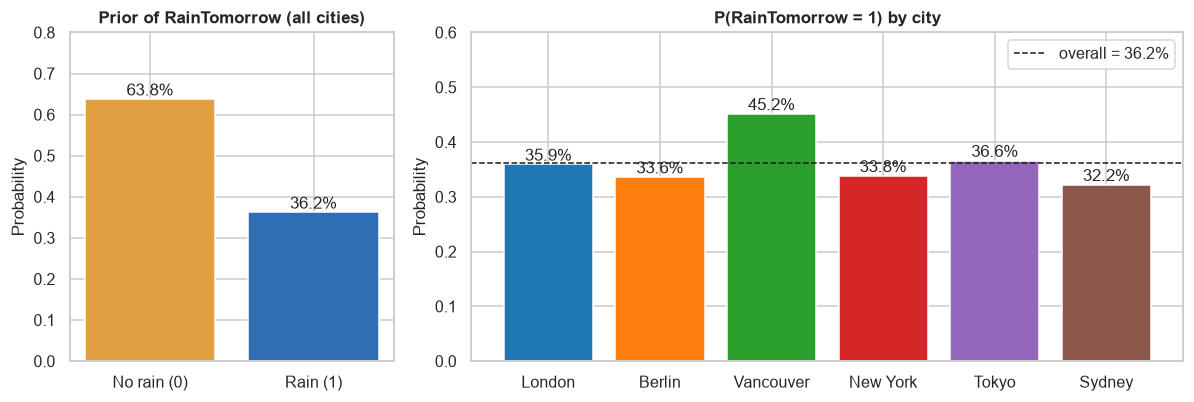

In [7]:
p_overall = df.RainTomorrow.value_counts(normalize=True).sort_index()
p_city = df.groupby("location").RainTomorrow.mean().loc[CITY_ORDER]
print("P(RainTomorrow) overall:\n", p_overall.round(3))
print("\nP(RainTomorrow=1) by city:\n", p_city.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 2.2]})
ax = axes[0]
bars = ax.bar(["No rain (0)", "Rain (1)"], p_overall.values, color=[RAIN_COLORS[0], RAIN_COLORS[1]])
ax.bar_label(bars, labels=[f"{v:.1%}" for v in p_overall.values])
ax.set(title="Prior of RainTomorrow (all cities)", ylabel="Probability", ylim=(0, 0.8))
ax = axes[1]
bars = ax.bar(p_city.index, p_city.values, color=[PALETTE[c] for c in p_city.index])
ax.bar_label(bars, labels=[f"{v:.1%}" for v in p_city.values])
ax.axhline(p_overall[1], ls="--", c="k", lw=1, label=f"overall = {p_overall[1]:.1%}")
ax.set(title="P(RainTomorrow = 1) by city", ylabel="Probability", ylim=(0, 0.6))
ax.legend(loc="upper right")
fig.tight_layout(); save(fig, "fig01_target_prior")

### 2.3 Prior distributions – continuous variables (PDF)

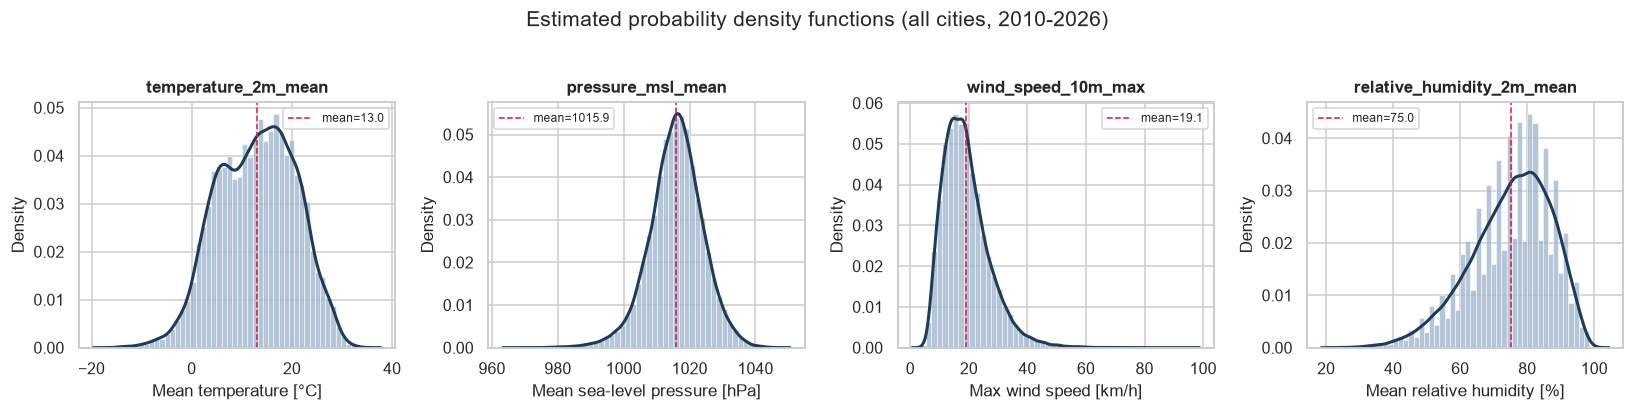

                              mean    std  skew    min     max
temperature_2m_mean          12.97   7.74 -0.16  -16.8    34.9
pressure_msl_mean          1015.89   8.08 -0.30  966.2  1047.6
wind_speed_10m_max           19.07   7.89  1.23    3.5    95.9
relative_humidity_2m_mean    75.05  11.97 -0.60   23.0   100.0


In [8]:
cont = [("temperature_2m_mean", "Mean temperature [°C]"),
        ("pressure_msl_mean", "Mean sea-level pressure [hPa]"),
        ("wind_speed_10m_max", "Max wind speed [km/h]"),
        ("relative_humidity_2m_mean", "Mean relative humidity [%]")]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (c, lab) in zip(axes, cont):
    sns.histplot(df[c], stat="density", bins=50, color="#9DB4CC", ax=ax, edgecolor=None)
    sns.kdeplot(df[c], ax=ax, color="#1F3B5A", lw=2)
    ax.axvline(df[c].mean(), color="crimson", ls="--", lw=1, label=f"mean={df[c].mean():.1f}")
    ax.set(title=c, xlabel=lab, ylabel="Density"); ax.legend(fontsize=8)
fig.suptitle("Estimated probability density functions (all cities, 2010-2026)", y=1.03)
fig.tight_layout(); save(fig, "fig02_continuous_pdf")
print(df[[c for c, _ in cont]].agg(["mean", "std", "skew", "min", "max"]).T.round(2))

In [9]:
# precipitation is zero-inflated: show the share of exactly-zero days and the distribution of the positive part
p = df.precipitation_sum
print(f"P(precipitation_sum = 0)   = {(p == 0).mean():.3f}")
print(f"P(0 < precipitation < 1mm) = {((p > 0) & (p < 1)).mean():.3f}")
print(f"P(precipitation >= 1mm)    = {(p >= 1).mean():.3f}")
print("quantiles of positive part:", p[p > 0].quantile([.5, .9, .99]).round(1).to_dict())

P(precipitation_sum = 0)   = 0.455
P(0 < precipitation < 1mm) = 0.183
P(precipitation >= 1mm)    = 0.362
quantiles of positive part: {0.5: 2.2, 0.9: 15.9, 0.99: 45.2}


### 2.4 Prior distributions – categorical variables (bar charts)

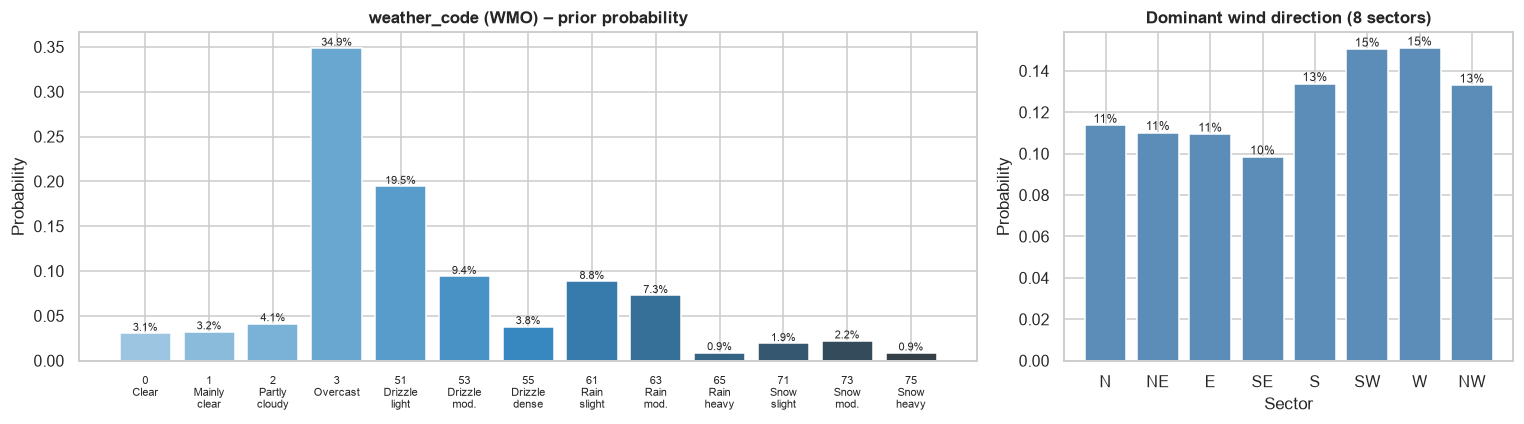

weather_code
0     0.0306
1     0.0323
2     0.0414
3     0.3487
51    0.1945
53    0.0941
55    0.0381
61    0.0885
63    0.0727
65    0.0091
71    0.0192
73    0.0221
75    0.0087
Name: proportion, dtype: float64


In [10]:
WMO = {0: "Clear", 1: "Mainly clear", 2: "Partly cloudy", 3: "Overcast", 45: "Fog", 48: "Rime fog",
       51: "Drizzle light", 53: "Drizzle mod.", 55: "Drizzle dense", 61: "Rain slight", 63: "Rain mod.",
       65: "Rain heavy", 71: "Snow slight", 73: "Snow mod.", 75: "Snow heavy"}
def wmo_family(code):
    if code <= 1: return "Clear"
    if code <= 3: return "Cloudy"
    if code in (45, 48): return "Fog"
    if 51 <= code <= 57: return "Drizzle"
    if 61 <= code <= 67 or 80 <= code <= 82: return "Rain"
    if 71 <= code <= 77 or code in (85, 86): return "Snow"
    if code >= 95: return "Thunderstorm"
    return "Other"
SECTORS = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
def wind_sector(deg):
    return pd.Categorical(np.array(SECTORS)[(((deg + 22.5) % 360) // 45).astype(int)], categories=SECTORS, ordered=False)
df["weather_code_label"] = df.weather_code.map(WMO).fillna(df.weather_code.astype(str))
df["wind_sector"] = wind_sector(df.wind_direction_10m_dominant)

wc = df.weather_code.value_counts(normalize=True).sort_index()
ws = df.wind_sector.value_counts(normalize=True).reindex(SECTORS)
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
labels = [f"{k}\n" + str(WMO.get(k, k)).replace(" ", "\n") for k in wc.index]
bars = ax.bar(range(len(wc)), wc.values, color=sns.color_palette("Blues_d", len(wc)))
ax.set_xticks(range(len(wc)), labels, fontsize=7)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in wc.values], fontsize=7.5)
ax.set(title="weather_code (WMO) – prior probability", ylabel="Probability")
ax = axes[1]
bars = ax.bar(SECTORS, ws.values, color="#5B8DB8")
ax.bar_label(bars, labels=[f"{v:.0%}" for v in ws.values], fontsize=8)
ax.set(title="Dominant wind direction (8 sectors)", ylabel="Probability", xlabel="Sector")
fig.tight_layout(); save(fig, "fig03_categorical_priors")
print(wc.round(4))

### 2.5 Balance and representativeness

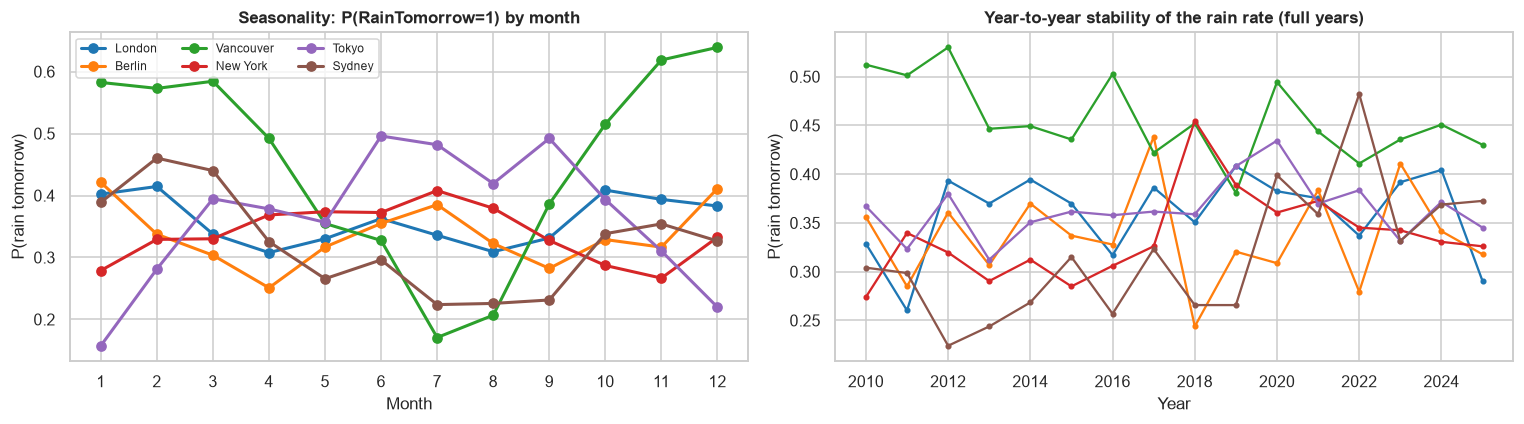

Imbalance ratio (0:1) = 1.76

Std of yearly rain rate per city:
 location
London       0.043
Berlin       0.050
Vancouver    0.041
New York     0.044
Tokyo        0.030
Sydney       0.067
dtype: float64


In [11]:
df["year"], df["month"] = df.date.dt.year, df.date.dt.month
rate_ym = df.groupby(["location", "month"]).RainTomorrow.mean().unstack(0)[CITY_ORDER]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for c in CITY_ORDER:
    axes[0].plot(rate_ym.index, rate_ym[c], marker="o", lw=2, color=PALETTE[c], label=c)
axes[0].set(title="Seasonality: P(RainTomorrow=1) by month", xlabel="Month", ylabel="P(rain tomorrow)",
            xticks=range(1, 13))
axes[0].legend(ncol=3, fontsize=8)
rate_y = df[df.year < df.year.max()].groupby(["location", "year"]).RainTomorrow.mean().unstack(0)[CITY_ORDER]
for c in CITY_ORDER:
    axes[1].plot(rate_y.index, rate_y[c], marker=".", lw=1.5, color=PALETTE[c], label=c)
axes[1].set(title="Year-to-year stability of the rain rate (full years)", xlabel="Year", ylabel="P(rain tomorrow)")
fig.tight_layout(); save(fig, "fig04_seasonality_years")
print("Imbalance ratio (0:1) =", round((1 - df.RainTomorrow.mean()) / df.RainTomorrow.mean(), 2))
print("\nStd of yearly rain rate per city:\n", rate_y.std().round(3))

## 3. Relationships between features
### 3.1 Correlation matrix

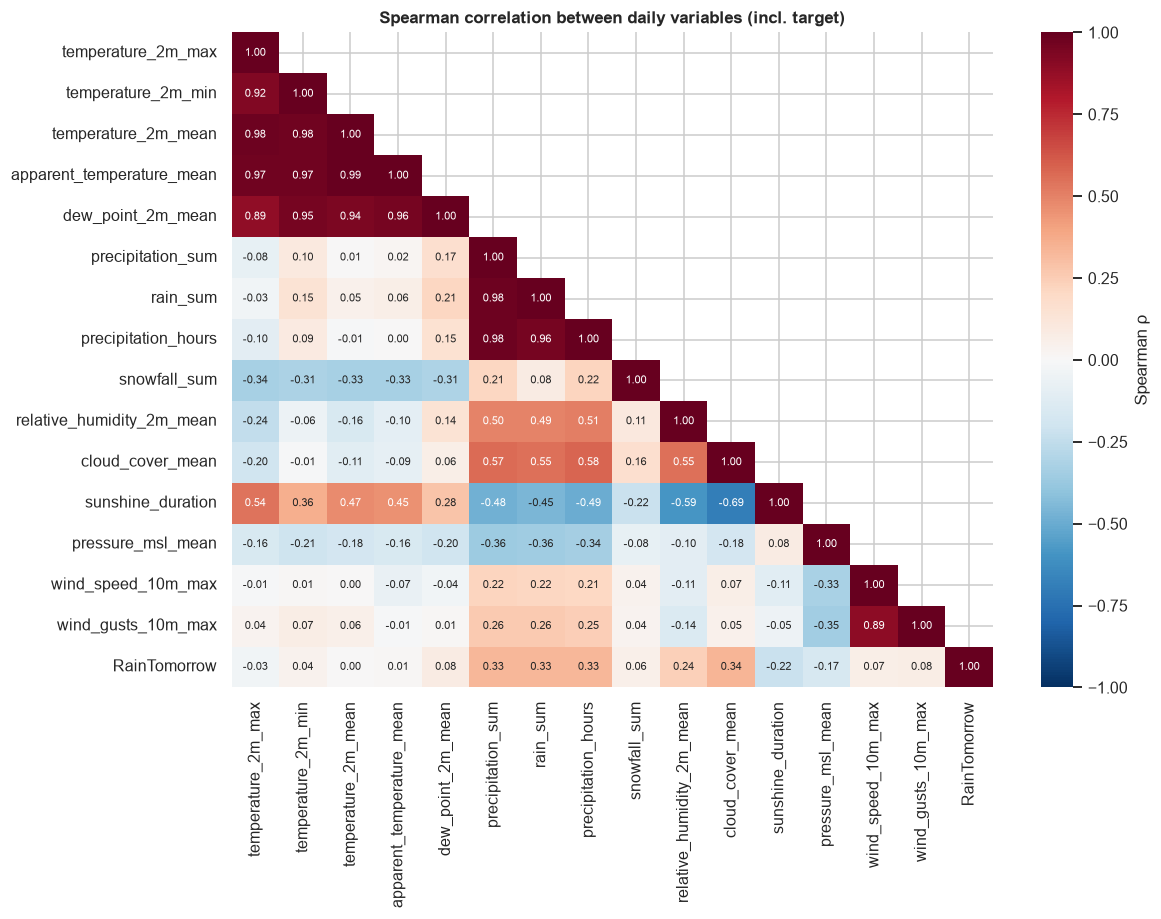

In [12]:
num_cols = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "apparent_temperature_mean",
            "dew_point_2m_mean", "precipitation_sum", "rain_sum", "precipitation_hours", "snowfall_sum",
            "relative_humidity_2m_mean", "cloud_cover_mean", "sunshine_duration", "pressure_msl_mean",
            "wind_speed_10m_max", "wind_gusts_10m_max", "RainTomorrow"]
corr = df[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 8.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"label": "Spearman ρ"}, ax=ax)
ax.set_title("Spearman correlation between daily variables (incl. target)")
fig.tight_layout(); save(fig, "fig05_correlation")

### 3.2 Expected relationships: the temperature block and precipitation vs. rain

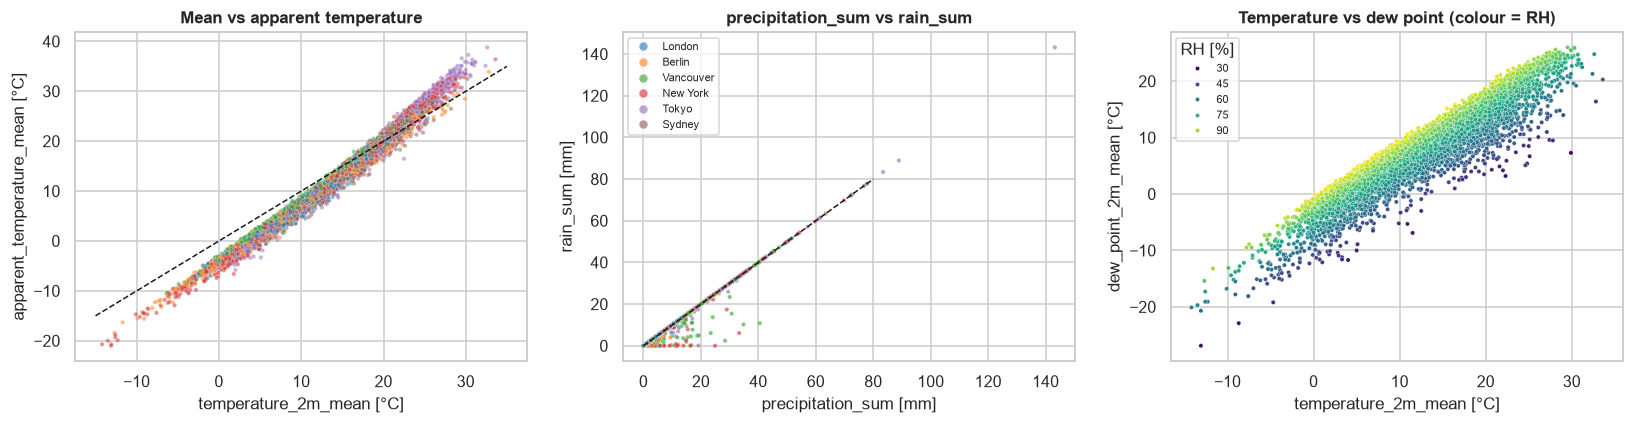

share of days with rain_sum == precipitation_sum: 0.952
days with snow (precip > rain) by city:
 location
London       0.023
Berlin       0.076
Vancouver    0.098
New York     0.066
Tokyo        0.024
Sydney       0.000
dtype: float64


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
s = df.sample(6000, random_state=0)
sns.scatterplot(data=s, x="temperature_2m_mean", y="apparent_temperature_mean", hue="location",
                hue_order=CITY_ORDER, palette=PALETTE, s=8, alpha=.5, ax=axes[0], legend=False)
axes[0].plot([-15, 35], [-15, 35], "k--", lw=1)
axes[0].set(title="Mean vs apparent temperature", xlabel="temperature_2m_mean [°C]", ylabel="apparent_temperature_mean [°C]")
sns.scatterplot(data=s, x="precipitation_sum", y="rain_sum", hue="location", hue_order=CITY_ORDER,
                palette=PALETTE, s=8, alpha=.6, ax=axes[1])
axes[1].plot([0, 80], [0, 80], "k--", lw=1)
axes[1].set(title="precipitation_sum vs rain_sum", xlabel="precipitation_sum [mm]", ylabel="rain_sum [mm]")
axes[1].legend(fontsize=7, markerscale=2)
sns.scatterplot(data=s, x="temperature_2m_mean", y="dew_point_2m_mean", hue="relative_humidity_2m_mean",
                palette="viridis", s=8, ax=axes[2])
axes[2].set(title="Temperature vs dew point (colour = RH)", xlabel="temperature_2m_mean [°C]", ylabel="dew_point_2m_mean [°C]")
axes[2].legend(title="RH [%]", fontsize=7)
fig.tight_layout(); save(fig, "fig06_expected_relations")
diff = df.precipitation_sum - df.rain_sum
print("share of days with rain_sum == precipitation_sum:", round((diff.abs() < 1e-9).mean(), 3))
print("days with snow (precip > rain) by city:\n", (diff > 0.05).groupby(df.location).mean().loc[CITY_ORDER].round(3))

### 3.3 Less expected relationships: rain persistence, pressure tendency and wind direction

           P(R_t+1 | dry today)  P(R_t+1 | rain today)   lift
location                                                     
London                    0.258                  0.539  2.085
Berlin                    0.242                  0.521  2.150
Vancouver                 0.251                  0.696  2.775
New York                  0.280                  0.453  1.617
Tokyo                     0.271                  0.531  1.962
Sydney                    0.209                  0.560  2.678


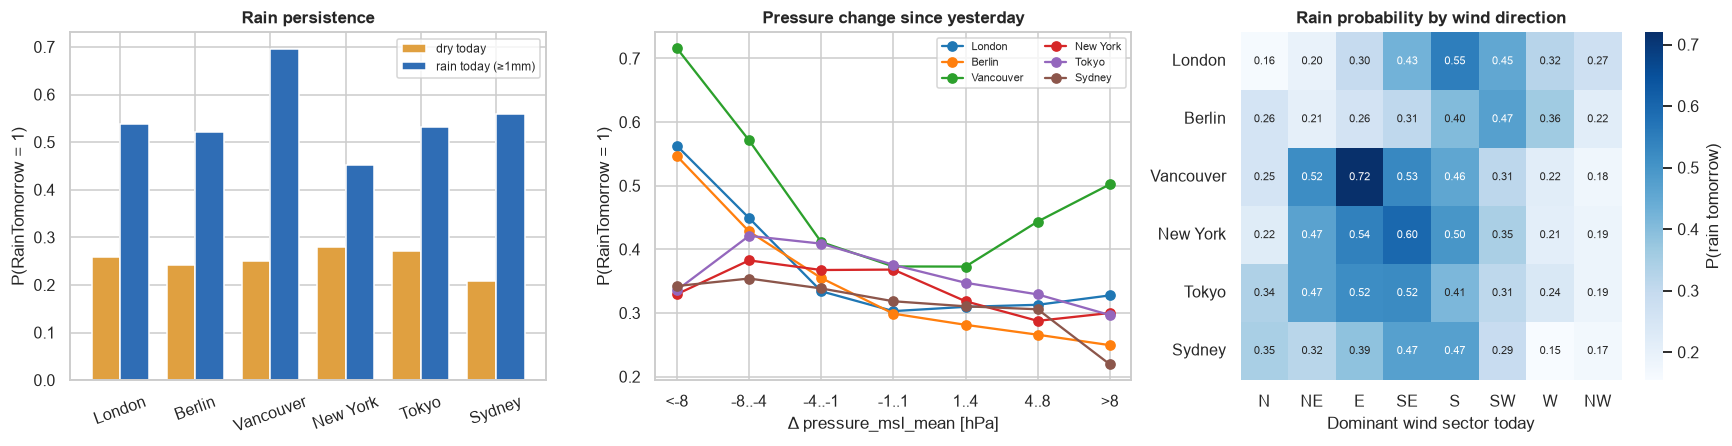


P(rain tomorrow) by pressure-change bin (all cities):
 dp_bin
<-8       0.471
-8..-4    0.434
-4..-1    0.368
-1..1     0.340
1..4      0.324
4..8      0.322
>8        0.322
Name: RainTomorrow, dtype: float64


In [14]:
d = df.sort_values(["location", "date"]).copy()
d["rain_today"] = (d.precipitation_sum >= 1).astype(int)
d["pressure_change"] = d.groupby("location").pressure_msl_mean.diff()
# (a) persistence: P(rain tomorrow | rain today)
pers = d.groupby(["location", "rain_today"]).RainTomorrow.mean().unstack().loc[CITY_ORDER]
pers.columns = ["P(R_t+1 | dry today)", "P(R_t+1 | rain today)"]
pers["lift"] = pers.iloc[:, 1] / pers.iloc[:, 0]
print(pers.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(len(CITY_ORDER)); w = .38
axes[0].bar(x - w/2, pers.iloc[:, 0], w, color=RAIN_COLORS[0], label="dry today")
axes[0].bar(x + w/2, pers.iloc[:, 1], w, color=RAIN_COLORS[1], label="rain today (≥1mm)")
axes[0].set_xticks(x, CITY_ORDER, rotation=20)
axes[0].set(title="Rain persistence", ylabel="P(RainTomorrow = 1)"); axes[0].legend(fontsize=8)
# (b) pressure tendency
d["dp_bin"] = pd.cut(d.pressure_change, [-60, -8, -4, -1, 1, 4, 8, 60],
                     labels=["<-8", "-8..-4", "-4..-1", "-1..1", "1..4", "4..8", ">8"])
pt = d.groupby(["dp_bin", "location"], observed=True).RainTomorrow.mean().unstack()[CITY_ORDER]
for c in CITY_ORDER:
    axes[1].plot(pt.index.astype(str), pt[c], marker="o", color=PALETTE[c], label=c)
axes[1].set(title="Pressure change since yesterday", xlabel="Δ pressure_msl_mean [hPa]", ylabel="P(RainTomorrow = 1)")
axes[1].legend(fontsize=7, ncol=2)
# (c) wind direction per city
wd = d.groupby(["location", "wind_sector"], observed=True).RainTomorrow.mean().unstack()[SECTORS].loc[CITY_ORDER]
sns.heatmap(wd, annot=True, fmt=".2f", cmap="Blues", ax=axes[2], cbar_kws={"label": "P(rain tomorrow)"}, annot_kws={"size": 7})
axes[2].set(title="Rain probability by wind direction", xlabel="Dominant wind sector today", ylabel="")
fig.tight_layout(); save(fig, "fig07_unexpected_relations")
print("\nP(rain tomorrow) by pressure-change bin (all cities):\n", d.groupby("dp_bin", observed=True).RainTomorrow.mean().round(3))

### 3.4 Suspected predictors – univariate evidence

In [15]:
def auc_of(x, y):
    # AUC of a single feature = P(x_rain > x_dry); computed from the Mann-Whitney U statistic
    ok = x.notna()
    x, y = x[ok], y[ok]
    u = stats.mannwhitneyu(x[y == 1], x[y == 0]).statistic
    a = u / ((y == 1).sum() * (y == 0).sum())
    return max(a, 1 - a), ("+" if a >= .5 else "-")

feat = [c for c in num_cols if c != "RainTomorrow"] + ["wind_direction_10m_dominant", "weather_code"]
rows = []
for c in feat:
    a, sign = auc_of(d[c], d.RainTomorrow)
    r, _ = stats.pointbiserialr(d.RainTomorrow, d[c].fillna(d[c].median()))
    rows.append((c, r, a, sign))
uni = pd.DataFrame(rows, columns=["feature", "point_biserial_r", "univariate_AUC", "direction"]).set_index("feature")
uni = uni.sort_values("univariate_AUC", ascending=False)
uni.round(3)

,point_biserial_r,univariate_AUC,direction
feature,,,
cloud_cover_mean,0.336,0.705,+
precipitation_hours,0.333,0.691,+
precipitation_sum,0.230,0.691,+
rain_sum,0.225,0.689,+
weather_code,0.297,0.688,+
relative_humidity_2m_mean,0.235,0.644,+
sunshine_duration,-0.231,0.633,-
pressure_msl_mean,-0.173,0.601,-
wind_direction_10m_dominant,-0.136,0.589,-


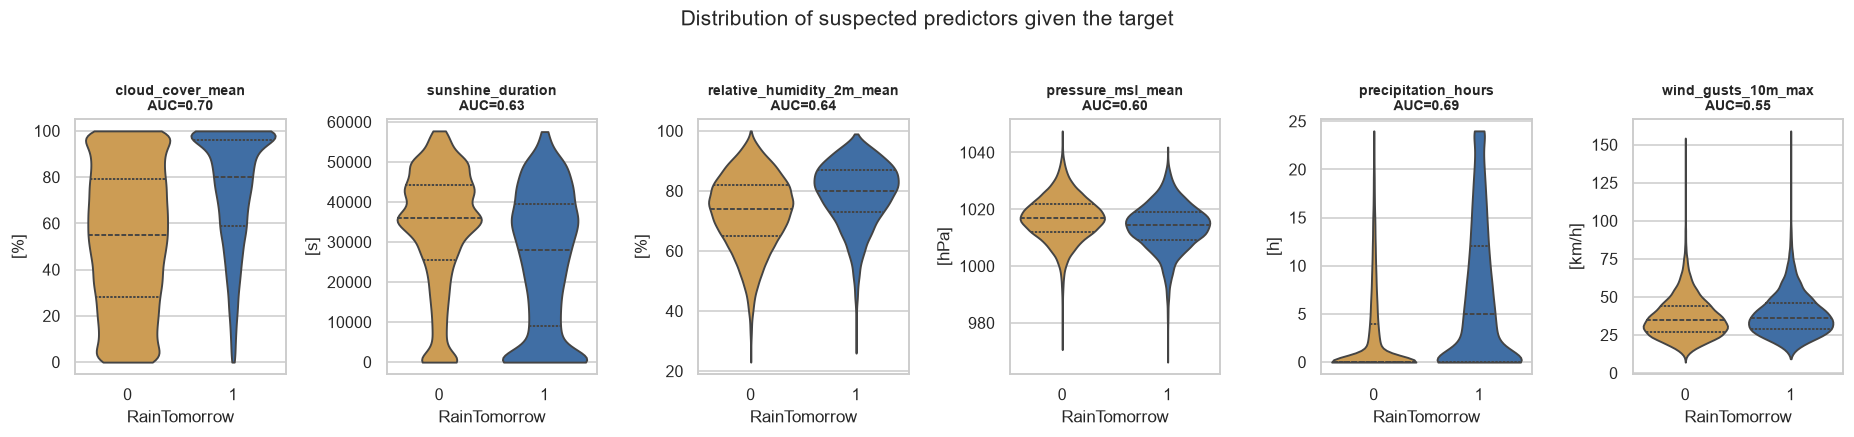

In [16]:
top = ["cloud_cover_mean", "sunshine_duration", "relative_humidity_2m_mean", "pressure_msl_mean", "precipitation_hours", "wind_gusts_10m_max"]
units = {"cloud_cover_mean": "%", "sunshine_duration": "s", "relative_humidity_2m_mean": "%",
         "pressure_msl_mean": "hPa", "precipitation_hours": "h", "wind_gusts_10m_max": "km/h"}
fig, axes = plt.subplots(1, 6, figsize=(17, 3.8))
for ax, c in zip(axes, top):
    sns.violinplot(data=d, x="RainTomorrow", y=c, hue="RainTomorrow", palette=RAIN_COLORS, ax=ax,
                   cut=0, inner="quartile", legend=False)
    ax.set(title=f"{c}\nAUC={uni.loc[c, 'univariate_AUC']:.2f}", xlabel="RainTomorrow", ylabel=f"[{units[c]}]")
    ax.title.set_fontsize(9)
fig.suptitle("Distribution of suspected predictors given the target", y=1.04)
fig.tight_layout(); save(fig, "fig08_suspected_predictors")

### 3.5 Candidate variables for removal – checking the assumption

In [17]:
pairs = [("temperature_2m_mean", "temperature_2m_max"), ("temperature_2m_mean", "temperature_2m_min"),
         ("temperature_2m_mean", "apparent_temperature_mean"), ("precipitation_sum", "rain_sum"),
         ("wind_speed_10m_max", "wind_gusts_10m_max"), ("cloud_cover_mean", "sunshine_duration"),
         ("temperature_2m_mean", "dew_point_2m_mean")]
red = pd.DataFrame([(a, b, df[a].corr(df[b]), df[a].corr(df[b], method="spearman")) for a, b in pairs],
                   columns=["var A", "var B", "Pearson r", "Spearman ρ"])
print(red.round(3).to_string(index=False))
print("\nshare of zero snowfall days by city:\n", (df.snowfall_sum == 0).groupby(df.location).mean().loc[CITY_ORDER].round(3))
# weather_code is derived from the other variables (reanalysis): check consistency with precipitation
wet_code = df.weather_code >= 51
print("\nP(weather_code is a precipitation code | precipitation_sum>0)  =", round(wet_code[df.precipitation_sum > 0].mean(), 3))
print("P(weather_code is a precipitation code | precipitation_sum==0) =", round(wet_code[df.precipitation_sum == 0].mean(), 3))
print(pd.crosstab(pd.cut(df.precipitation_sum, [-.1, 0, .1, 1, 2.5, 7.6, 1e3]), df.weather_code))

              var A                     var B  Pearson r  Spearman ρ
temperature_2m_mean        temperature_2m_max      0.981       0.981
temperature_2m_mean        temperature_2m_min      0.976       0.976
temperature_2m_mean apparent_temperature_mean      0.992       0.994
  precipitation_sum                  rain_sum      0.987       0.981
 wind_speed_10m_max        wind_gusts_10m_max      0.902       0.895
   cloud_cover_mean         sunshine_duration     -0.674      -0.690
temperature_2m_mean         dew_point_2m_mean      0.936       0.939

share of zero snowfall days by city:
 location
London       0.975
Berlin       0.918
Vancouver    0.901
New York     0.931
Tokyo        0.975
Sydney       1.000
Name: snowfall_sum, dtype: float64

P(weather_code is a precipitation code | precipitation_sum>0)  = 1.0
P(weather_code is a precipitation code | precipitation_sum==0) = 0.004
weather_code         0     1     2      3     51    53   55    61    63   65   71   73   75
precipitation_sum 

## 4. Data quality
### 4.1 Missing values

In [18]:
miss = sensed.isna().sum()
print("missing values per column (sensed_data):\n", miss[miss > 0] if miss.any() else "none")
print("\nrows with any missing value:", int(sensed.isna().any(axis=1).sum()), "of", len(sensed))
if miss.any():
    print(sensed[sensed.isna().any(axis=1)].groupby("location").date.agg(["min", "max", "size"]))
# gaps in the date sequence
gaps = sensed.sort_values(["location", "date"]).groupby("location").date.diff().dt.days
print("\ndate gaps (>1 day) per city:", gaps[gaps > 1].groupby(sensed.location).size().to_dict() or "none")
print("expected days per city:", (sensed.date.max() - sensed.date.min()).days + 1,
      "| actual:", sensed.groupby("location").size().to_dict())

missing values per column (sensed_data):
 none

rows with any missing value: 0 of 36888

date gaps (>1 day) per city: none
expected days per city: 6148 | actual: {'Berlin': 6148, 'London': 6148, 'New York': 6148, 'Sydney': 6148, 'Tokyo': 6148, 'Vancouver': 6148}


### 4.2 Illogical / impossible values

In [19]:
checks = {
    "temperature_2m_min > temperature_2m_max": df.temperature_2m_min > df.temperature_2m_max,
    "mean temp outside [min, max]": (df.temperature_2m_mean < df.temperature_2m_min - .05) | (df.temperature_2m_mean > df.temperature_2m_max + .05),
    "rain_sum > precipitation_sum": df.rain_sum > df.precipitation_sum + 1e-6,
    "negative precipitation / rain / snow": (df[["precipitation_sum", "rain_sum", "snowfall_sum"]] < 0).any(axis=1),
    "precipitation_hours outside [0, 24]": ~df.precipitation_hours.between(0, 24),
    "precipitation_hours>0 but precipitation_sum==0": (df.precipitation_hours > 0) & (df.precipitation_sum == 0),
    "precipitation_sum>0 but precipitation_hours==0": (df.precipitation_sum > 0) & (df.precipitation_hours == 0),
    "wind direction outside [0, 360]": ~df.wind_direction_10m_dominant.between(0, 360),
    "gust < wind speed": df.wind_gusts_10m_max < df.wind_speed_10m_max - .05,
    "relative humidity outside [0, 100]": ~df.relative_humidity_2m_mean.between(0, 100),
    "cloud cover outside [0, 100]": ~df.cloud_cover_mean.between(0, 100),
    "dew point > mean temperature": df.dew_point_2m_mean > df.temperature_2m_mean + .05,
    "sunshine > 24h": df.sunshine_duration > 86400,
    "pressure outside [940, 1060] hPa": ~df.pressure_msl_mean.between(940, 1060),
    "snowfall in Sydney": (df.location == "Sydney") & (df.snowfall_sum > 0),
}
qc = pd.DataFrame({"violations": {k: int(v.sum()) for k, v in checks.items()}})
qc["share"] = (qc.violations / len(df)).round(5)
qc

,violations,share
temperature_2m_min > temperature_2m_max,0,0.00000
"mean temp outside [min, max]",1,0.00003
rain_sum > precipitation_sum,0,0.00000
negative precipitation / rain / snow,0,0.00000
"precipitation_hours outside [0, 24]",0,0.00000
precipitation_hours>0 but precipitation_sum==0,0,0.00000
precipitation_sum>0 but precipitation_hours==0,0,0.00000
"wind direction outside [0, 360]",0,0.00000
gust < wind speed,1,0.00003
"relative humidity outside [0, 100]",0,0.00000


In [20]:
# extreme (but possibly real) values: robust z-score per city
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median() * 1.4826
    return (s - med) / (mad if mad > 0 else 1)
ext_cols = ["temperature_2m_mean", "pressure_msl_mean", "wind_speed_10m_max", "relative_humidity_2m_mean"]
z = df.groupby("location")[ext_cols].transform(robust_z)
print("rows with |robust z| > 5 per variable:\n", (z.abs() > 5).sum())
print("\nTop-5 daily precipitation events:")
print(df.nlargest(5, "precipitation_sum")[["location", "date", "precipitation_sum", "precipitation_hours", "weather_code"]].to_string(index=False))

rows with |robust z| > 5 per variable:
 temperature_2m_mean           0
pressure_msl_mean             6
wind_speed_10m_max           44
relative_humidity_2m_mean     1
dtype: int64

Top-5 daily precipitation events:
location       date  precipitation_sum  precipitation_hours  weather_code
New York 2022-10-04              183.6                 24.0            65
   Tokyo 2019-10-12              150.5                 24.0            65
   Tokyo 2026-06-03              143.2                 18.0            65
  Sydney 2020-02-09              138.7                 24.0            65
   Tokyo 2013-10-16              133.9                 10.0            65


## 5. Data preparation

In [21]:
prep = df.sort_values(["location", "date"]).copy()

# 5.1 imputation (only if needed): time interpolation inside each city, never across cities
cont_cols = [c for c in num_cols if c != "RainTomorrow"] + ["wind_direction_10m_dominant"]
n_missing_before = int(prep[cont_cols].isna().sum().sum())
prep[cont_cols] = prep.groupby("location")[cont_cols].transform(lambda s: s.interpolate(limit=3, limit_direction="both"))
print("missing cells before/after imputation:", n_missing_before, "/", int(prep[cont_cols].isna().sum().sum()))

# 5.2 derived features
g = prep.groupby("location")
prep["temp_range"] = prep.temperature_2m_max - prep.temperature_2m_min                  # diurnal range: small under clouds
prep["dewpoint_depression"] = prep.temperature_2m_mean - prep.dew_point_2m_mean          # how close air is to saturation
prep["rain_today"] = (prep.precipitation_sum >= 1.0).astype(int)                         # same definition as the target
prep["pressure_change_1d"] = g.pressure_msl_mean.diff()                                  # falling pressure → approaching low
prep["humidity_change_1d"] = g.relative_humidity_2m_mean.diff()
prep["temp_change_1d"] = g.temperature_2m_mean.diff()
prep["precip_yesterday"] = g.precipitation_sum.shift(1)
prep["precip_3d_sum"] = g.precipitation_sum.transform(lambda s: s.rolling(3, min_periods=1).sum())
prep["rain_streak"] = g.rain_today.transform(lambda s: s.groupby((s != s.shift()).cumsum()).cumcount().add(1).where(s == 1, 0))
prep["wind_dir_sin"] = np.sin(np.deg2rad(prep.wind_direction_10m_dominant))             # circular encoding: 359° ≈ 1°
prep["wind_dir_cos"] = np.cos(np.deg2rad(prep.wind_direction_10m_dominant))
doy = prep.date.dt.day_of_year
prep["doy_sin"], prep["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
south = prep.location.eq("Sydney")
month_adj = np.where(south, (prep.month + 5) % 12 + 1, prep.month)                        # shift seasons in the south
prep["season"] = pd.Categorical(np.select([np.isin(month_adj, [12, 1, 2]), np.isin(month_adj, [3, 4, 5]),
                                           np.isin(month_adj, [6, 7, 8])], ["Winter", "Spring", "Summer"], "Autumn"),
                                categories=["Winter", "Spring", "Summer", "Autumn"], ordered=True)

# 5.3 discretisation
prep["precip_intensity"] = pd.cut(prep.precipitation_sum, [-0.01, 0, 1, 2.5, 7.6, 1e4],
                                  labels=["none", "trace (<1)", "light", "moderate", "heavy"])   # WMO/AMS-style thresholds
prep["temp_band"] = pd.cut(prep.temperature_2m_mean, [-50, 0, 10, 20, 50], labels=["freezing", "cold", "mild", "warm"])
prep["weather_family"] = prep.weather_code.map(wmo_family)
prep["cloud_okta_band"] = pd.cut(prep.cloud_cover_mean, [-1, 25, 50, 87.5, 100], labels=["clear", "scattered", "broken", "overcast"])

# 5.4 feature selection: drop redundant / leaking / low-value columns
drop = {
    "rain_sum": "≈ precipitation_sum (ρ≈0.99); differs only on snow days",
    "temperature_2m_max": "redundant with temperature_2m_mean (r≈0.98); kept via temp_range",
    "temperature_2m_min": "redundant with temperature_2m_mean (r≈0.98); kept via temp_range",
    "apparent_temperature_mean": "function of temperature + humidity + wind (r≈0.99 with mean temp)",
    "snowfall_sum": "zero on 90-100% of days (95% overall); its information = precipitation_sum - rain_sum",
    "wind_direction_10m_dominant": "replaced by sin/cos encoding (circular variable)",
    "weather_code_label": "display helper",
}
# first day of every city has no 'yesterday' → drop these 6 rows (lags undefined)
prep = prep.dropna(subset=["pressure_change_1d", "precip_yesterday"])
prepared = prep.drop(columns=list(drop) + ["year"])
prepared.to_csv(PROC / "prepared_dataset.csv", index=False, date_format="%Y-%m-%d")
print("dropped columns:"); [print(f"  - {k}: {v}") for k, v in drop.items()]
print("\nprepared dataset:", prepared.shape)
prepared.head()

missing cells before/after imputation: 0 / 0


dropped columns:
  - rain_sum: ≈ precipitation_sum (ρ≈0.99); differs only on snow days
  - temperature_2m_max: redundant with temperature_2m_mean (r≈0.98); kept via temp_range
  - temperature_2m_min: redundant with temperature_2m_mean (r≈0.98); kept via temp_range
  - apparent_temperature_mean: function of temperature + humidity + wind (r≈0.99 with mean temp)
  - snowfall_sum: zero on 90-100% of days (95% overall); its information = precipitation_sum - rain_sum
  - wind_direction_10m_dominant: replaced by sin/cos encoding (circular variable)
  - weather_code_label: display helper

prepared dataset: (36876, 34)


,location,date,weather_code,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,relative_humidity_2m_mean,dew_point_2m_mean,pressure_msl_mean,cloud_cover_mean,sunshine_duration,wind_gusts_10m_max,RainTomorrow,wind_sector,month,temp_range,dewpoint_depression,rain_today,pressure_change_1d,humidity_change_1d,temp_change_1d,precip_yesterday,precip_3d_sum,rain_streak,wind_dir_sin,wind_dir_cos,doy_sin,doy_cos,season,precip_intensity,temp_band,weather_family,cloud_okta_band
1,Berlin,2010-01-02,71,-3.2,1.1,9.0,15.8,90,-4.7,1011.5,97,2114.82,23.0,0,NW,1,4.5,1.5,1,13.3,4.0,-0.6,3.2,4.3,2,-0.587785,0.809017,0.034398,0.999408,Winter,light,freezing,Snow,overcast
2,Berlin,2010-01-03,71,-6.8,0.0,0.0,7.3,93,-7.7,1020.2,94,12470.87,19.4,0,NE,1,4.1,0.9,0,8.7,3.0,-3.6,1.1,4.3,0,0.754710,0.656059,0.051584,0.998669,Winter,none,freezing,Snow,overcast
3,Berlin,2010-01-04,3,-7.7,0.0,0.0,13.0,90,-9.1,1017.6,92,0.00,23.8,0,SW,1,3.3,1.4,0,-2.6,-3.0,-0.9,0.0,1.1,0,-0.573576,-0.819152,0.068755,0.997634,Winter,none,freezing,Cloudy,overcast
4,Berlin,2010-01-05,3,-7.8,0.0,0.0,11.2,88,-9.5,1010.3,90,18052.82,21.6,0,S,1,6.3,1.7,0,-7.3,-2.0,-0.1,0.0,0.0,0,0.069756,-0.997564,0.085906,0.996303,Winter,none,freezing,Cloudy,overcast
5,Berlin,2010-01-06,3,-8.5,0.0,0.0,8.6,89,-9.9,1005.4,93,0.00,14.8,0,NE,1,7.8,1.4,0,-4.9,1.0,-0.7,0.0,0.0,0,0.707107,0.707107,0.103031,0.994678,Winter,none,freezing,Cloudy,overcast


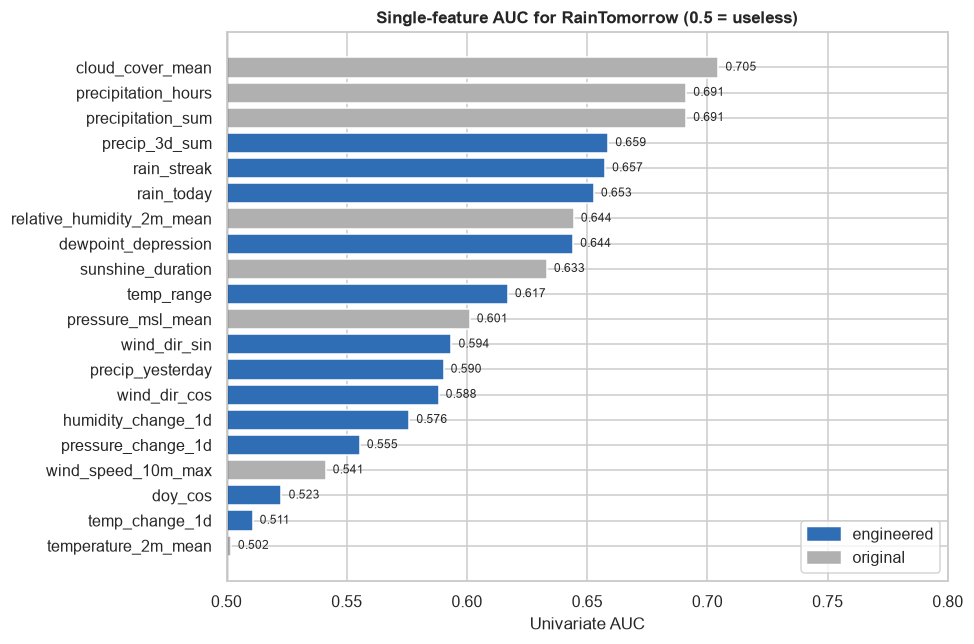

,feature,AUC,kind
12,cloud_cover_mean,0.705,original
15,precipitation_hours,0.691,original
16,precipitation_sum,0.691,original
5,precip_3d_sum,0.659,engineered
8,rain_streak,0.657,engineered
7,rain_today,0.653,engineered
14,relative_humidity_2m_mean,0.644,original
0,dewpoint_depression,0.644,engineered
13,sunshine_duration,0.633,original
1,temp_range,0.617,engineered


In [22]:
new_feats = ["dewpoint_depression", "temp_range", "pressure_change_1d", "humidity_change_1d", "temp_change_1d",
             "precip_3d_sum", "precip_yesterday", "rain_today", "rain_streak", "wind_dir_sin", "wind_dir_cos", "doy_cos"]
orig_feats = ["cloud_cover_mean", "sunshine_duration", "relative_humidity_2m_mean", "precipitation_hours",
              "precipitation_sum", "pressure_msl_mean", "temperature_2m_mean", "wind_speed_10m_max"]
rows = [(f, auc_of(prep[f], prep.RainTomorrow)[0], "engineered" if f in new_feats else "original") for f in new_feats + orig_feats]
au = pd.DataFrame(rows, columns=["feature", "AUC", "kind"]).sort_values("AUC")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(au.feature, au.AUC - .5, left=.5, color=au.kind.map({"engineered": "#2F6DB5", "original": "#B0B0B0"}))
for y, v in enumerate(au.AUC): ax.text(v + .003, y, f"{v:.3f}", va="center", fontsize=8)
ax.axvline(.5, c="k", lw=.8)
ax.set(title="Single-feature AUC for RainTomorrow (0.5 = useless)", xlabel="Univariate AUC", xlim=(.5, .8))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#2F6DB5", label="engineered"), Patch(color="#B0B0B0", label="original")], loc="lower right")
fig.tight_layout(); save(fig, "fig09_feature_auc")
au.sort_values("AUC", ascending=False).round(3)

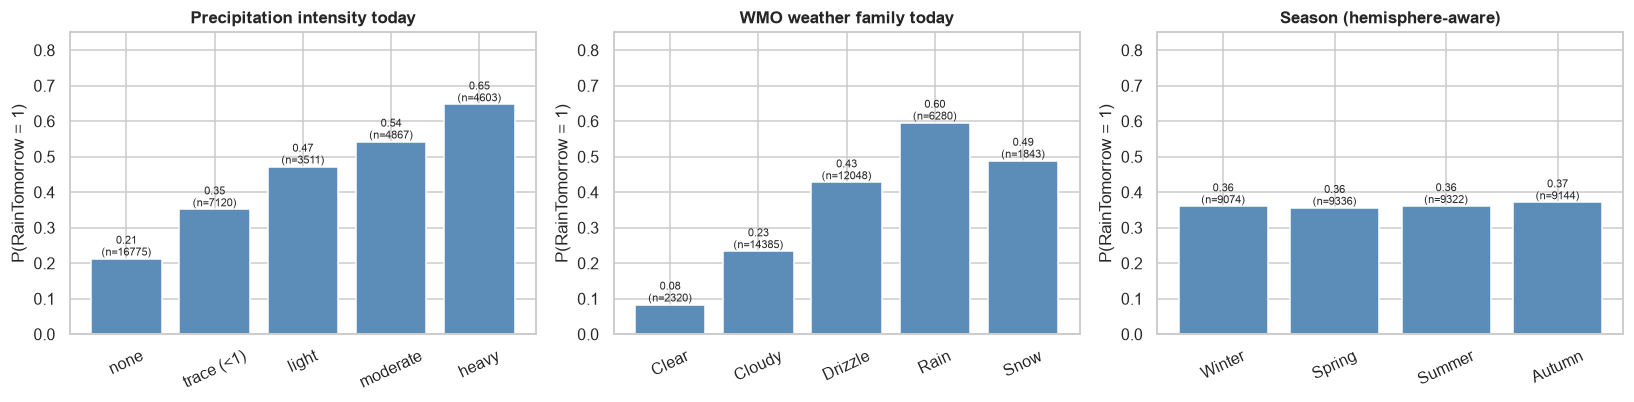

In [23]:
# discretised variables vs target
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c, t in zip(axes, ["precip_intensity", "weather_family", "season"],
                    ["Precipitation intensity today", "WMO weather family today", "Season (hemisphere-aware)"]):
    r = prep.groupby(c, observed=True).RainTomorrow.agg(["mean", "size"])
    bars = ax.bar(r.index.astype(str), r["mean"], color="#5B8DB8")
    ax.bar_label(bars, labels=[f"{m:.2f}\n(n={n})" for m, n in zip(r["mean"], r["size"])], fontsize=7)
    ax.set(title=t, ylabel="P(RainTomorrow = 1)", ylim=(0, .85)); ax.tick_params(axis="x", rotation=25)
fig.tight_layout(); save(fig, "fig10_discretised")

## 6. Extra analysis – naive baselines and generalisation over time

In [24]:
# What accuracy would trivial rules achieve? These are the numbers a learned model in Part B must beat.
test = prep[prep.date >= "2024-01-01"]; train = prep[prep.date < "2024-01-01"]
clim = train.groupby(["location", "month"]).RainTomorrow.mean()
pred_clim = (test.set_index(["location", "month"]).index.map(clim) >= .5).astype(int)
base = pd.DataFrame({
    "majority (always 0)": [(test.RainTomorrow == 0).mean()],
    "persistence (tomorrow = today)": [(test.RainTomorrow == test.rain_today).mean()],
    "climatology (city×month majority)": [(test.RainTomorrow == pred_clim).mean()],
}, index=["accuracy on 2024-2026"]).T
print(base.round(3))
pb = test.groupby("location").apply(lambda t: pd.Series({
        "majority": (t.RainTomorrow == 0).mean(), "persistence": (t.RainTomorrow == t.rain_today).mean()}),
        include_groups=False).loc[CITY_ORDER]
print("\nper city:\n", pb.round(3))
# drift: is the base rate in the recent period different from the past?
drift = pd.DataFrame({"2010-2023": train.groupby("location").RainTomorrow.mean(),
                      "2024-2026": test.groupby("location").RainTomorrow.mean()}).loc[CITY_ORDER]
drift["diff"] = drift.iloc[:, 1] - drift.iloc[:, 0]
print("\nrain rate train vs recent:\n", drift.round(3))

                                   accuracy on 2024-2026
majority (always 0)                                0.634
persistence (tomorrow = today)                     0.688
climatology (city×month majority)                  0.641

per city:
            majority  persistence
location                        
London        0.654        0.684
Berlin        0.672        0.705
Vancouver     0.582        0.732
New York      0.655        0.640
Tokyo         0.625        0.663
Sydney        0.617        0.703

rain rate train vs recent:
            2010-2023  2024-2026   diff
location                              
London         0.362      0.346 -0.016
Berlin         0.338      0.328 -0.010
Vancouver      0.458      0.418 -0.041
New York       0.337      0.345  0.008
Tokyo          0.364      0.375  0.011
Sydney         0.310      0.383  0.073


In [25]:
# Markov view of rain: transition probabilities of the daily rain state per city
mk = prep.groupby("location").apply(lambda t: pd.Series({
        "P(1|0)": t.loc[t.rain_today == 0, "RainTomorrow"].mean(),
        "P(1|1)": t.loc[t.rain_today == 1, "RainTomorrow"].mean(),
        "mean wet-spell length [days]": 1 / (1 - t.loc[t.rain_today == 1, "RainTomorrow"].mean())}),
        include_groups=False).loc[CITY_ORDER]
mk.round(3)

,P(1|0),P(1|1),mean wet-spell length [days]
location,,,
London,0.259,0.539,2.169
Berlin,0.242,0.521,2.087
Vancouver,0.251,0.695,3.284
New York,0.280,0.453,1.828
Tokyo,0.271,0.531,2.134
Sydney,0.209,0.560,2.271


In [26]:
# Which features would be available if the Part-B test JSONs contain only the 10 required variables?
required_only = ["precipitation_hours", "precipitation_sum", "temp_range", "temp_change_1d", "precip_yesterday", "wind_speed_10m_max", "wind_dir_sin", "wind_dir_cos", "doy_cos", "rain_streak",
                 "temperature_2m_mean", "precip_3d_sum", "rain_today"]
avail = pd.DataFrame({"available with the 10 required vars": ["yes" if f in required_only else "no (needs extra var)"
                      for f in au.sort_values('AUC', ascending=False).feature]},
                     index=au.sort_values('AUC', ascending=False).feature)
avail

,available with the 10 required vars
feature,
cloud_cover_mean,no (needs extra var)
precipitation_hours,yes
precipitation_sum,yes
precip_3d_sum,yes
rain_streak,yes
rain_today,yes
relative_humidity_2m_mean,no (needs extra var)
dewpoint_depression,no (needs extra var)
sunshine_duration,no (needs extra var)
